# **Newton–Pepys Problem (1693)**
___


#### **A Counterintuitive Probability Problem**

In 1693, Samuel Pepys asked Isaac Newton which of the following three events was most likely when rolling fair dice:

1. Obtaining at least one 6 when rolling 6 dice.
2. Obtaining at least two 6s when rolling 12 dice.
3. Obtaining at least three 6s when rolling 18 dice.

At first glance, the third event might appear more likely because it involves a greater number of dice. However, increasing the number of dice also increases the number of successful outcomes required.

This problem explores the relationship between the number of independent trials and the probability of achieving a specified number of successes.

### Objective

We will investigate all three scenarios using theoretical probability and Monte Carlo simulation.
Our analysis will use the Binomial Distribution to calculate exact probabilities and independent random dice experiments to verify the mathematical results.
We will also examine why increasing the number of trials does not necessarily increase the probability of an event when its success threshold increases simultaneously.


___
## **1. Problem Assumptions**

For a mathematically valid comparison, we assume:

* Every die is fair, with six equally likely outcomes.
* The probability of obtaining a 6 on any die is \(1/6\).
* The probability of not obtaining a 6 is \(5/6\).
* All dice rolls are independent.
* Each scenario consists of a fixed number of dice.
* A successful outcome means obtaining at least the specified number of sixes.

### Defining Success

For this problem, we define:

$$
\text{Success} = \text{Rolling a 6}
$$

$$
\text{Failure} = \text{Rolling any number other than 6}
$$

Therefore,

$$
p=P(\text{Success})=\frac16
$$

$$
1-p=P(\text{Failure})=\frac56
$$

### The Three Experiments

| Experiment | Number of dice (\(n\)) | Required successes (\(r\)) |
| ---------- | ---------------------: | -------------------------: |
| A          |                      6 |                 At least 1 |
| B          |                     12 |                 At least 2 |
| C          |                     18 |                 At least 3 |


___
## **2. Mathematical Model**

The Newton–Pepys problem involves a fixed number of independent trials, where each trial has two possible outcomes: success or failure.

This satisfies the conditions of a Binomial Distribution.

Let \(X\) represent the number of sixes obtained when rolling \(n\) dice.

Then,

$$
X\sim\operatorname{Binomial}(n,p)
$$

where:

* \(n\) = number of dice.
* \(p=1/6\) = probability of obtaining a 6.
* \(X\) = number of successful outcomes.

The probability of obtaining exactly \(k\) sixes is:

$$
\boxed{
P(X=k)=\binom nk p^k(1-p)^{n-k}
}
$$

However, the problem asks for at least a specified number of sixes.

Using the complement rule:

$$
\boxed{
P(X\geq r)=1-P(X<r)
}
$$

Therefore,

$$
\boxed{
P(X\geq r)=1-\sum_{k=0}^{r-1}
\binom nk p^k(1-p)^{n-k}
}
$$

We will use this expression to calculate the theoretical probabilities for all three experiments.


**Importing Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import binom

**Visualisation theme**

In [2]:
import matplotlib as mpl
from matplotlib.ticker import PercentFormatter

COLORS = {
    "background": "#0B1020",
    "panel": "#121A2B",
    "text": "#F1F5F9",
    "muted": "#94A3B8",
    "cyan": "#22D3EE",
    "coral": "#FB7185",
    "gold": "#FBBF24",
    "green": "#34D399",
    "grid": "#293449"
}

mpl.rcParams.update({
    "figure.facecolor": COLORS["background"],
    "axes.facecolor": COLORS["panel"],
    "axes.edgecolor": COLORS["grid"],
    "axes.labelcolor": COLORS["text"],
    "axes.titlecolor": COLORS["text"],
    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"],
    "text.color": COLORS["text"],
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": False,
    "savefig.facecolor": COLORS["background"],
    "savefig.dpi": 200
})

___
## **3. Theoretical Probability**

The objective is to calculate the probability of obtaining at least a specified number of sixes in each experiment.

We will use the complement rule:

$$
P(X\geq r)=1-P(X<r)
$$

For a Binomial Distribution,

$$
P(X=k)=\binom nk p^k(1-p)^{n-k}
$$

where \(n\) is the number of dice, \(k\) is the exact number of sixes, and \(p=1/6\).

### _Experiment A: At least one 6 with 6 dice_

The complement of obtaining at least one 6 is obtaining no sixes.

$$
P(X\geq1)=1-P(X=0)
$$

$$
\boxed{P(X\geq1)=1-\left(\frac56\right)^6}
$$

### _Experiment B: At least two 6s with 12 dice_

The complement consists of obtaining either zero or exactly one 6.

$$
P(X\geq2)=1-P(X=0)-P(X=1)
$$

$$
\boxed{
P(X\geq2)=
1-\left(\frac56\right)^{12}
-12\left(\frac16\right)\left(\frac56\right)^{11}
}
$$

The coefficient 12 represents the number of possible positions in which the single 6 can occur.

### _Experiment C: At least three 6s with 18 dice_

The complement consists of zero, one, or exactly two sixes.

$$
P(X\geq3)=1-\sum_{k=0}^{2}
\binom{18}{k}
\left(\frac16\right)^k
\left(\frac56\right)^{18-k}
$$

The combination coefficient accounts for all possible arrangements of the successful dice.

These three expressions represent the same Binomial probability model, with different numbers of trials and success thresholds.


**Calculate probabilities manually**

In [3]:
p = 1 / 6

manual_probabilities = {
    "Experiment A": 1 - (1 - p) ** 6,

    "Experiment B": (
        1
        - (1 - p) ** 12
        - 12 * p * (1 - p) ** 11
    ),

    "Experiment C": (
        1
        - (1 - p) ** 18
        - 18 * p * (1 - p) ** 17
        - 153 * p**2 * (1 - p) ** 16
    )
}

manual_probabilities

{'Experiment A': 0.6651020233196159,
 'Experiment B': 0.6186673737323085,
 'Experiment C': 0.5973456859477229}

**Calculate Probabilities using Scipy**

In [6]:
experiments = {
    "Experiment A": {"n": 6, "r": 1},
    "Experiment B": {"n": 12, "r": 2},
    "Experiment C": {"n": 18, "r": 3}
}

theoretical_results = {}

for name, settings in experiments.items():
    n = settings["n"]
    r = settings["r"]

    theoretical_results[name] = binom.sf(
        r - 1,
        n,
        p
    )

theoretical_results

{'Experiment A': np.float64(0.6651020233196159),
 'Experiment B': np.float64(0.6186673737323085),
 'Experiment C': np.float64(0.5973456859477229)}

**Verify both approach**

In [7]:
theoretical_df = pd.DataFrame({
    "Experiment": experiments.keys(),
    "Number of Dice": [6, 12, 18],
    "Required Sixes": [1, 2, 3],
    "Manual Probability": manual_probabilities.values(),
    "SciPy Probability": theoretical_results.values()
})

theoretical_df["Probability (%)"] = (
    theoretical_df["SciPy Probability"] * 100
)

theoretical_df["Absolute Difference"] = abs(
    theoretical_df["Manual Probability"]
    - theoretical_df["SciPy Probability"]
)

theoretical_df

,Experiment,Number of Dice,Required Sixes,Manual Probability,SciPy Probability,Probability (%),Absolute Difference
0,Experiment A,6,1,0.665102,0.665102,66.510202,0.0
1,Experiment B,12,2,0.618667,0.618667,61.866737,0.0
2,Experiment C,18,3,0.597346,0.597346,59.734569,0.0


___
## **4. Understanding the Binomial Probability Distribution**

The Binomial Distribution describes the probability of obtaining exactly \(k\) successes in \(n\) independent trials.

In our problem, success means rolling a 6.
For each experiment, the possible number of successes ranges from zero to the total number of dice.
The probability mass function is:

$$
P(X=k)=\binom nk
\left(\frac16\right)^k
\left(\frac56\right)^{n-k}
$$

By examining the complete distribution, we can understand how probability is distributed across different numbers of successful dice rolls.
This is particularly useful because the original problem asks for cumulative events, not the probability of exactly one particular number of sixes.


**Generate distribution data**

In [8]:
distribution_data = []

for name, settings in experiments.items():
    n = settings["n"]

    for k in range(n + 1):
        probability = binom.pmf(k, n, p)

        distribution_data.append({
            "Experiment": name,
            "Number of Sixes": k,
            "Probability": probability
        })

distribution_df = pd.DataFrame(distribution_data)

distribution_df.head(10)

,Experiment,Number of Sixes,Probability
0,Experiment A,0,0.334898
1,Experiment A,1,0.401878
2,Experiment A,2,0.200939
3,Experiment A,3,0.053584
4,Experiment A,4,0.008038
5,Experiment A,5,0.000643
6,Experiment A,6,0.000021
7,Experiment B,0,0.112157
8,Experiment B,1,0.269176
9,Experiment B,2,0.296094


**Three Binomial distributions plot**

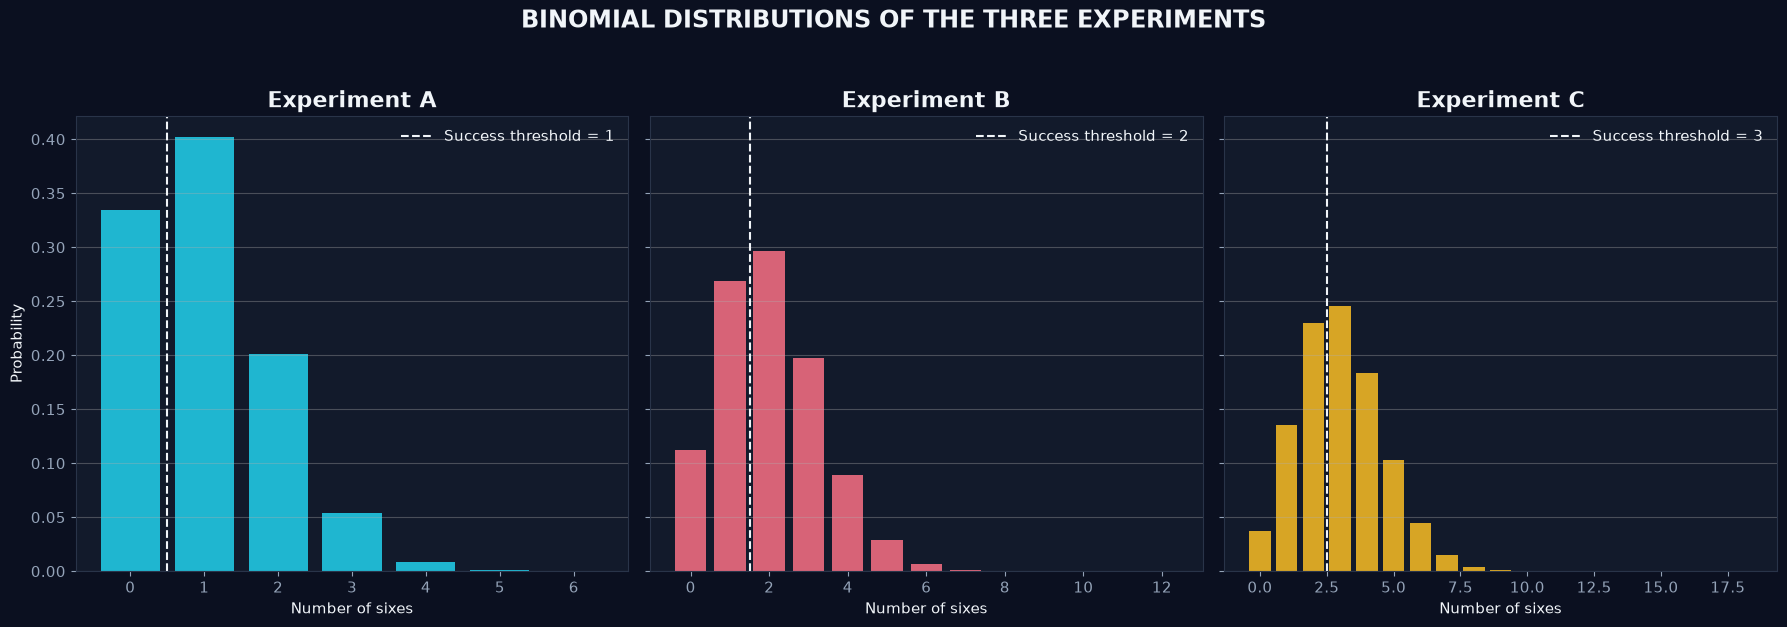

In [9]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    sharey=True
)

experiment_colors = [
    COLORS["cyan"],
    COLORS["coral"],
    COLORS["gold"]
]

for ax, (name, settings), color in zip(
    axes,
    experiments.items(),
    experiment_colors
):
    n = settings["n"]
    r = settings["r"]

    subset = distribution_df[
        distribution_df["Experiment"] == name
    ]

    ax.bar(
        subset["Number of Sixes"],
        subset["Probability"],
        color=color,
        alpha=0.85,
        edgecolor="none"
    )

    ax.axvline(
        r - 0.5,
        color=COLORS["text"],
        linestyle="--",
        linewidth=1.5,
        label=f"Success threshold = {r}"
    )

    ax.set_title(name)
    ax.set_xlabel("Number of sixes")
    ax.grid(axis="y", alpha=0.35)
    ax.legend()

axes[0].set_ylabel("Probability")

fig.suptitle(
    "BINOMIAL DISTRIBUTIONS OF THE THREE EXPERIMENTS",
    fontsize=17,
    fontweight="bold",
    color=COLORS["text"],
    y=1.04
)

plt.tight_layout()
plt.show()

Each distribution shows how likely different numbers of sixes are.The dashed line marks the minimum number of sixes required for success. The probability bars at and to the right of that threshold represent the event we're interested in.

___
## **5. Monte Carlo Simulation**

We will estimate the probability of each event using repeated independent dice experiments.

Each simulation consists of:

1. Rolling the specified number of dice.
2. Counting how many dice show a 6.
3. Checking whether the number of sixes meets the required threshold.
4. Recording the experiment as successful or unsuccessful.

The estimated probability is:

$$
\boxed{
\hat P(\text{Success})=
\frac{\text{Number of successful experiments}}
{\text{Total number of experiments}}
}
$$

We will perform 100,000 independent experiments for each scenario.

The simulated probabilities will then be compared with the theoretical values obtained from the Binomial Distribution.


**Simulate One experiment**

In [10]:
rng = np.random.default_rng(42)

n = 18

single_roll = rng.integers(
    1,
    7,
    size=n
)

number_of_sixes = np.sum(single_roll == 6)

print("Dice outcomes:", single_roll)
print("Number of sixes:", number_of_sixes)
print("At least 3 sixes:", number_of_sixes >= 3)

Dice outcomes: [1 5 4 3 3 6 1 5 2 1 4 6 5 5 5 5 4 1]
Number of sixes: 2
At least 3 sixes: False


**Stimulate 100,000 independent experiments**

In [11]:
N_SIMULATIONS = 100_000

simulation_results = {}

for name, settings in experiments.items():

    n = settings["n"]
    required = settings["r"]

    rolls = rng.integers(
        1,
        7,
        size=(N_SIMULATIONS, n)
    )

    sixes_per_experiment = np.sum(
        rolls == 6,
        axis=1
    )

    successful_experiments = (
        sixes_per_experiment >= required
    )

    simulation_results[name] = {
        "successes": successful_experiments.sum(),
        "simulated_probability": successful_experiments.mean(),
        "sixes_per_experiment": sixes_per_experiment
    }

**Compare theoretical and simulated results**

In [12]:
results_df = pd.DataFrame([
    {
        "Experiment": name,
        "Dice": experiments[name]["n"],
        "Required Sixes": experiments[name]["r"],
        "Successful Trials": simulation_results[name]["successes"],
        "Total Trials": N_SIMULATIONS,
        "Theoretical Probability": theoretical_results[name],
        "Simulated Probability": simulation_results[name]["simulated_probability"]
    }
    for name in experiments
])

results_df["Theoretical (%)"] = (
    results_df["Theoretical Probability"] * 100
)

results_df["Simulated (%)"] = (
    results_df["Simulated Probability"] * 100
)

results_df["Absolute Error (pp)"] = (
    results_df["Simulated (%)"]
    - results_df["Theoretical (%)"]
).abs()

results_df

,Experiment,Dice,Required Sixes,Successful Trials,Total Trials,Theoretical Probability,Simulated Probability,Theoretical (%),Simulated (%),Absolute Error (pp)
0,Experiment A,6,1,66281,100000,0.665102,0.66281,66.510202,66.281,0.229202
1,Experiment B,12,2,61916,100000,0.618667,0.61916,61.866737,61.916,0.049263
2,Experiment C,18,3,59913,100000,0.597346,0.59913,59.734569,59.913,0.178431


### **Experimental Results and Interpretation**

After performing 100,000 independent experiments for each scenario, we obtained the following results:

| Experiment                       | Theoretical Probability | Simulated Probability | Absolute Error |
| -------------------------------- | ----------------------: | --------------------: | -------------: |
| A: At least 1 six with 6 dice    |                66.5102% |              66.2810% |      0.2292 pp |
| B: At least 2 sixes with 12 dice |                61.8667% |              61.9160% |      0.0493 pp |
| C: At least 3 sixes with 18 dice |                59.7346% |              59.9130% |      0.1784 pp |

### Key Observations

**1. The theoretical ranking is preserved.**

Both theoretical calculations and Monte Carlo simulations produce the same ranking:

$$
P(A)>P(B)>P(C)
$$

The event involving six dice is more likely than the events involving twelve and eighteen dice.

**2. The simulated probabilities are close to theoretical values.**

All three absolute errors are relatively small, with the largest difference being approximately 0.2292 percentage points.

**3. Random variation is expected.**

Monte Carlo simulation does not guarantee an exact reproduction of theoretical probabilities. Each experiment is random, and finite sample sizes introduce sampling variability.

**4. The results support the mathematical model.**

The close agreement between the theoretical and simulated probabilities provides empirical evidence that our implementation is behaving as expected.

The experiment demonstrates how computational simulation can be used to investigate and validate mathematical probability models.


**Theory Vs Simulation plot.**

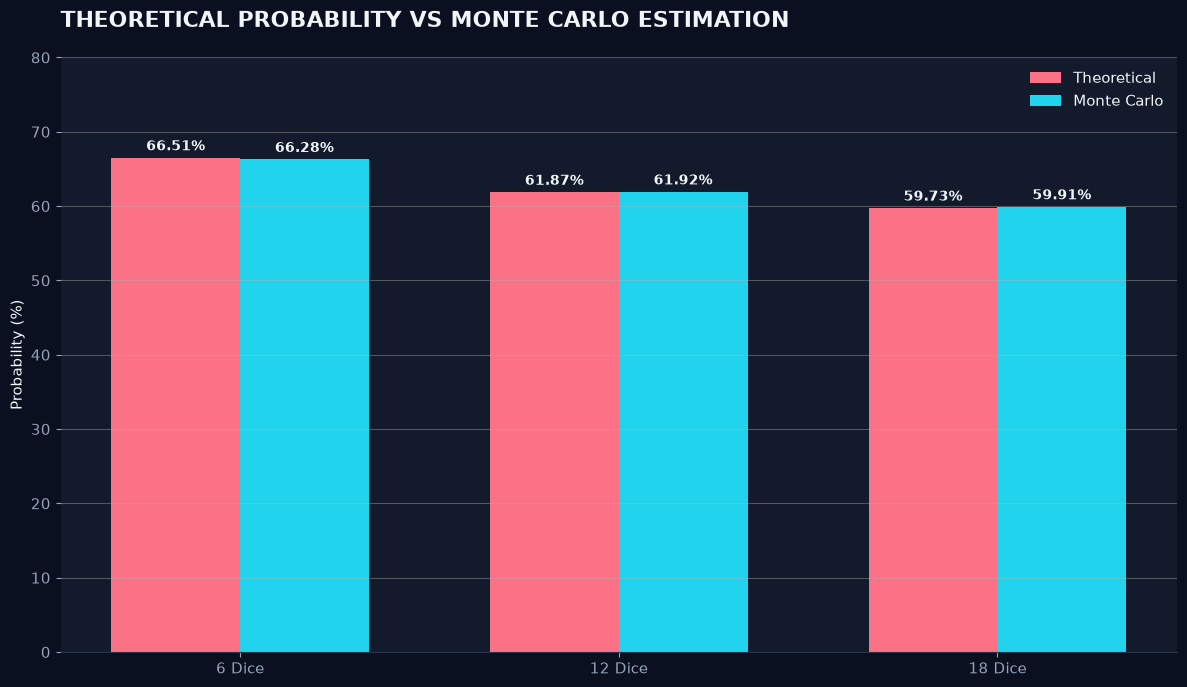

In [13]:
fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(results_df))
width = 0.34

theoretical_values = results_df["Theoretical (%)"]
simulated_values = results_df["Simulated (%)"]

bars1 = ax.bar(
    x - width / 2,
    theoretical_values,
    width,
    label="Theoretical",
    color=COLORS["coral"]
)

bars2 = ax.bar(
    x + width / 2,
    simulated_values,
    width,
    label="Monte Carlo",
    color=COLORS["cyan"]
)

ax.set_xticks(x)
ax.set_xticklabels(["6 Dice", "12 Dice", "18 Dice"])

ax.set_ylabel("Probability (%)")
ax.set_title(
    "THEORETICAL PROBABILITY VS MONTE CARLO ESTIMATION",
    loc="left",
    pad=22
)

ax.set_ylim(0, 80)
ax.grid(axis="y", alpha=0.4)
ax.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{bar.get_height():.2f}%",
            ha="center",
            fontsize=10,
            fontweight="bold"
        )

ax.spines[["top", "right", "left"]].set_visible(False)

plt.tight_layout()
plt.show()

**The probability Ranking - Cetral discovery of Newton Pepys**

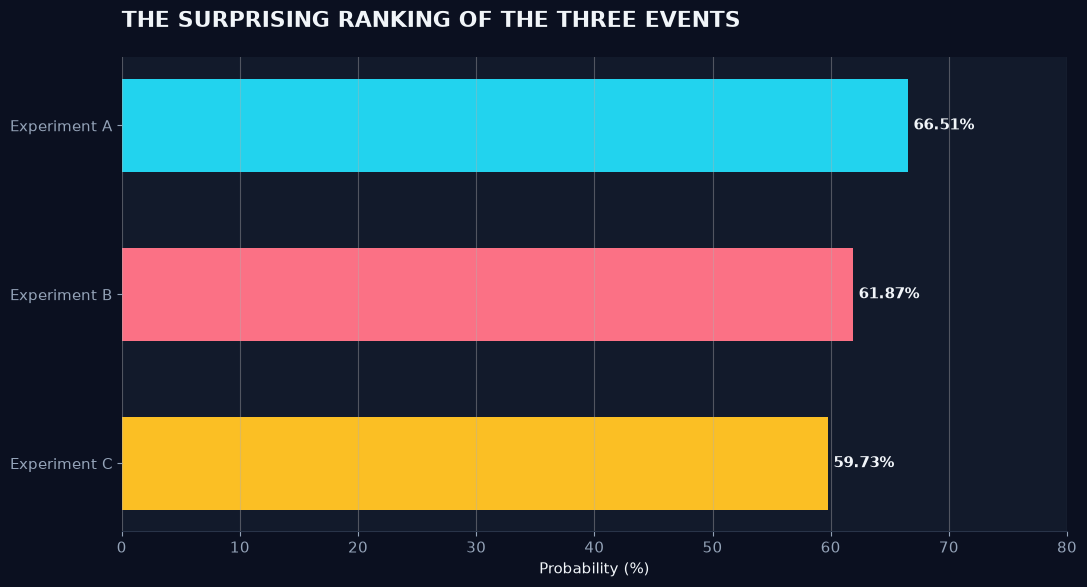

In [14]:
fig, ax = plt.subplots(figsize=(11, 6))

ranked_df = results_df.sort_values(
    "Theoretical Probability",
    ascending=True
)

bars = ax.barh(
    ranked_df["Experiment"],
    ranked_df["Theoretical (%)"],
    color=[
        COLORS["gold"],
        COLORS["coral"],
        COLORS["cyan"]
    ],
    height=0.55
)

for bar, value in zip(
    bars,
    ranked_df["Theoretical (%)"]
):
    ax.text(
        value + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontweight="bold"
    )

ax.set_xlim(0, 80)
ax.set_xlabel("Probability (%)")
ax.set_title(
    "THE SURPRISING RANKING OF THE THREE EVENTS",
    loc="left",
    pad=22
)

ax.grid(axis="x", alpha=0.4)
ax.spines[["top", "right", "left"]].set_visible(False)

plt.tight_layout()
plt.show()

The first event is the most likely, followed by the second and then the third.
This directly contradicts the intuition that more dice necessarily make the event more likely.

___
## **8. Convergence of Monte Carlo Estimates**

A Monte Carlo estimate is not fixed throughout a simulation. It changes as new random experiments are performed.

To examine this behaviour, we calculate the cumulative probability estimate after every experiment.

For the first \(m\) trials:

$$
\hat p_m=\frac{1}{m}\sum_{i=1}^{m}X_i
$$

where \(X_i\) is an indicator variable representing whether the \(i\)-th experiment was successful.

As the number of independent trials increases, the sample proportion is expected to converge towards the underlying theoretical probability.

This behaviour is explained by the **Law of Large Numbers**.

However, convergence does not mean that every new observation moves the estimate closer to its theoretical value. Random fluctuations can continue even at large sample sizes.


In [15]:
N_CONVERGENCE = 100_000

convergence_results = {}

for name, settings in experiments.items():

    n = settings["n"]
    required = settings["r"]

    rolls = rng.integers(
        1,
        7,
        size=(N_CONVERGENCE, n)
    )

    success = np.sum(rolls == 6, axis=1) >= required

    running_probability = (
        np.cumsum(success) /
        np.arange(1, N_CONVERGENCE + 1)
    )

    convergence_results[name] = running_probability

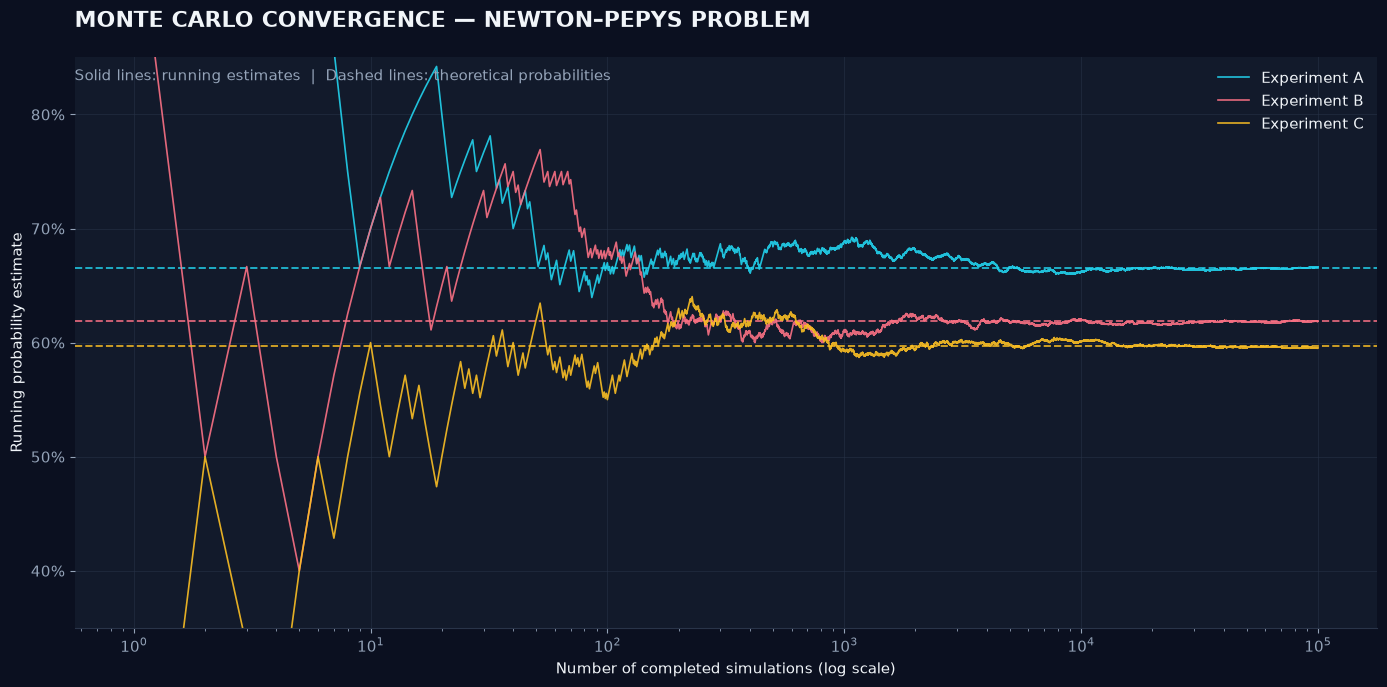

In [16]:
fig, ax = plt.subplots(figsize=(14, 7))

convergence_colors = {
    "Experiment A": COLORS["cyan"],
    "Experiment B": COLORS["coral"],
    "Experiment C": COLORS["gold"]
}

for name, running_probability in convergence_results.items():

    ax.plot(
        np.arange(1, N_CONVERGENCE + 1),
        running_probability,
        color=convergence_colors[name],
        linewidth=1.2,
        alpha=0.9,
        label=name
    )

    ax.axhline(
        theoretical_results[name],
        color=convergence_colors[name],
        linestyle="--",
        linewidth=1.4,
        alpha=0.8
    )

ax.set_xscale("log")
ax.set_ylim(0.35, 0.85)

ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.set_xlabel("Number of completed simulations (log scale)")
ax.set_ylabel("Running probability estimate")

ax.set_title(
    "MONTE CARLO CONVERGENCE — NEWTON–PEPYS PROBLEM",
    loc="left",
    pad=22
)

ax.text(
    0, 0.96,
    "Solid lines: running estimates  |  Dashed lines: theoretical probabilities",
    transform=ax.transAxes,
    color=COLORS["muted"]
)

ax.grid(color=COLORS["grid"], alpha=0.5)
ax.spines[["top", "right", "left"]].set_visible(False)

ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

he three curves represent the evolving estimates of the three probabilities.
The dashed horizontal lines represent their theoretical values.
Initially, the estimates fluctuate substantially because a small number of observations cannot reliably represent the underlying probability.
As more experiments are performed, the fluctuations generally become smaller, and the estimates stabilize around their respective theoretical values.

The key observation: All three experiments converge towards different probabilities, preserving the theoretical ranking.

___

## **09. The Central Insight**

The three experiments have a particularly interesting relationship.

For a Binomial Distribution:

$$
E[X]=np
$$

Since the probability of rolling a 6 is \(1/6\), the expected number of sixes is:

$$
E[X]=\frac n6
$$

For the three scenarios:

$$
E[X_A]=\frac66=1
$$

$$
E[X_B]=\frac{12}{6}=2
$$

$$
E[X_C]=\frac{18}{6}=3
$$

The required number of sixes is therefore equal to the expected number of sixes in every experiment.
Despite this similarity, the probabilities of meeting the respective thresholds are different:

$$
P(X_A\geq1)\approx66.51\%
$$

$$
P(X_B\geq2)\approx61.87\%
$$

$$
P(X_C\geq3)\approx59.73\%
$$

The key lesson is that the expected number of successes does not determine the probability of achieving at least that number.
The complete probability distribution matters.
This is why simply increasing the number of dice does not guarantee a higher probability of satisfying an increasingly demanding success condition.


___
## **10. Findings and Conclusion**

### Major Findings

1. **Theoretical ranking:** The first event is the most likely, followed by the second and third.

$$
P(A)>P(B)>P(C)
$$

2. **Monte Carlo validation:** Simulations of 100,000 experiments per scenario produced estimates close to the theoretical Binomial probabilities.

3. **Statistical variation:** Small differences between simulated and theoretical values are expected because Monte Carlo estimates are subject to sampling variability.

4. **Convergence:** As the number of independent experiments increases, the simulated probabilities generally stabilize around their theoretical values.

5. **Simulation precision:** The standard error decreases proportionally to \(1/\sqrt N\), demonstrating the relationship between sample size and estimation accuracy.


### Limitations

* The analysis assumes perfectly fair dice.
* All dice rolls are assumed to be independent.
* Only three specific combinations of dice counts and success thresholds were investigated.
* Monte Carlo estimates are subject to random sampling variability.
* The simulation results depend on the number of experiments and the random seed.

### Conclusion

The Newton–Pepys problem demonstrates that intuitive reasoning can be misleading when comparing probabilities.

Although increasing the number of dice increases the expected number of sixes, it does not necessarily increase the probability of achieving a proportionally higher success threshold.

The Binomial Distribution provides the theoretical framework for calculating these probabilities, while Monte Carlo simulation offers an experimental method to investigate and validate the results.

This study demonstrates the complementary roles of mathematical probability, statistical reasoning and computational simulation.

**The central lesson is simple: a higher expected number of successes does not automatically imply a higher probability of meeting a higher success threshold.**


___
## **11. Further Exploration**

The Newton–Pepys problem can be extended in several directions.

1. **Threshold analysis:** Investigate how the probability changes when the required number of sixes differs from the expected number.

2. **Dice count analysis:** Calculate the probability of obtaining at least one, two, three or more sixes for different numbers of dice.

3. **Probability sensitivity:** Investigate how changing the probability of success affects the three experiments.

4. **Simulation efficiency:** Compare the computational time required for different Monte Carlo sample sizes.

5. **Non-fair dice:** Investigate how the results change when the probability of rolling a 6 is different from \(1/6\).

These extensions can provide a deeper understanding of Binomial probability models and their applications in statistical analysis.


___

_Thanks for reading._

by

**Abdur Rahman (Rahven)**